Learned Policy:
[['↓' '→' '→' '↓']
 ['↓' 'X' '→' '↓']
 ['→' '→' '→' '↓']
 ['↑' '↑' 'X' 'G']]


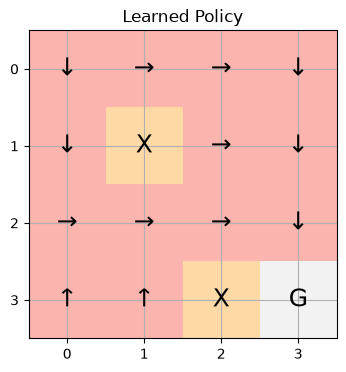

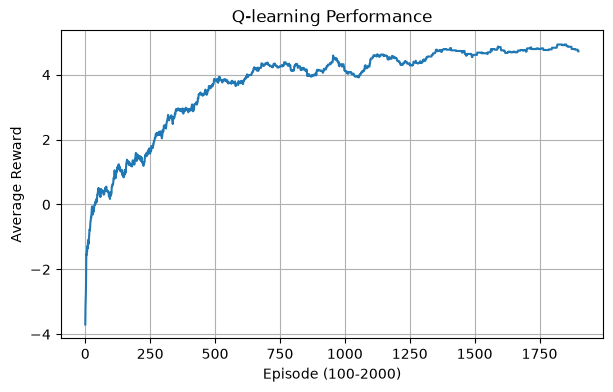

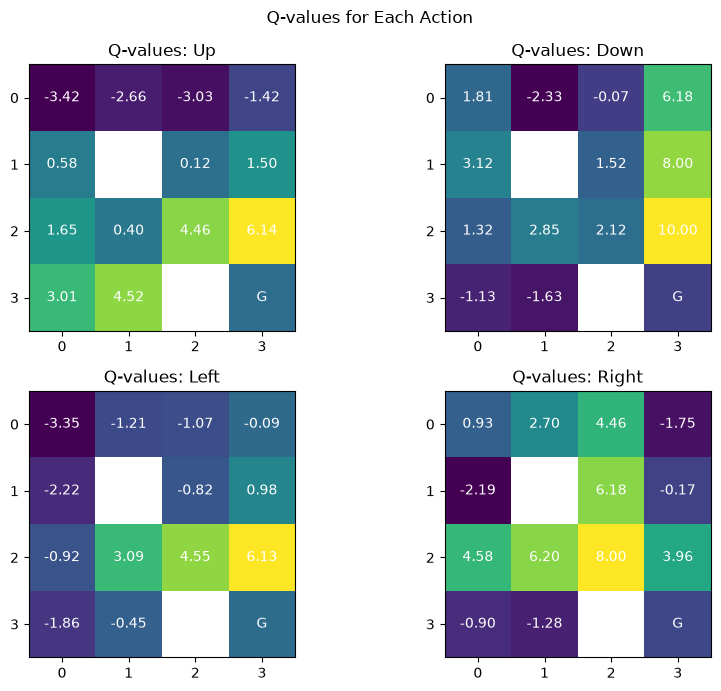


Q-values (Up, Down, Left, Right):
State (0, 0): [-3.42  1.81 -3.35  0.93]
State (0, 1): [-2.66 -2.33 -1.21  2.7 ]
State (0, 2): [-3.03 -0.07 -1.07  4.46]
State (0, 3): [-1.42  6.18 -0.09 -1.75]
State (1, 0): [ 0.58  3.12 -2.22 -2.19]
State (1, 1): Obstacle
State (1, 2): [ 0.12  1.52 -0.82  6.18]
State (1, 3): [ 1.5   8.    0.98 -0.17]
State (2, 0): [ 1.65  1.32 -0.92  4.58]
State (2, 1): [0.4  2.85 3.09 6.2 ]
State (2, 2): [4.46 2.12 4.55 8.  ]
State (2, 3): [ 6.14 10.    6.13  3.96]
State (3, 0): [ 3.01 -1.13 -1.86 -0.9 ]
State (3, 1): [ 4.52 -1.63 -0.45 -1.28]
State (3, 2): Obstacle
State (3, 3): Goal


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
np.random.seed(42)
# Create Grid
grid = np.array([
    [0, 0, 0, 0],
    [0, 1, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 1, 2]
])
rows, cols = grid.shape
# Actions: Up, Down, Left, Right
moves = [(-1,0), (1,0), (0,-1), (0,1)]
arrows = ['↑', '↓', '←', '→']
names = ['Up', 'Down', 'Left', 'Right'
Q = np.zeros((16, 4)
alpha = 0.1
gamma = 0.9
epsilon = 0.3
rewards = []
# Environment
def step(state, action):
    r, c = divmod(state, cols)
    dr, dc = moves[action]
    nr, nc = r + dr, c + dc
    if nr < 0 or nr >= rows or nc < 0 or nc >= cols:
        return state, -5, False
    if grid[nr, nc] == 1:
        return state, -5, False
    if grid[nr, nc] == 2:
        return nr * cols + nc, 10, True
    return nr * cols + nc, -1, False
    
# Q-Learning
for ep in range(2000):
    state = 0
    total = 0
    for _ in range(100):
        if np.random.random() < epsilon:
            action = np.random.randint(4)
        else:
            action = np.random.choice(
                np.flatnonzero(Q[state] == Q[state].max())
            )
        nxt, reward, done = step(state, action)
        Q[state, action] += alpha * (
            reward + gamma * Q[nxt].max() * (not done)
            - Q[state, action]
        )
        state = nxt
        total += reward
        if done:
            break
    rewards.append(total)
    epsilon = max(0.02, epsilon * 0.998)
    
# Create Learned Policy
policy = np.full((rows, cols), '', dtype=object)
for r in range(rows):
    for c in range(cols):
        if grid[r, c] == 1:
            policy[r, c] = 'X'
        elif grid[r, c] == 2:
            policy[r, c] = 'G'
        else:
            state = r * cols + c
            policy[r, c] = arrows[np.argmax(Q[state])]

print("Learned Policy:")
print(policy)

# 1. Display Learned Policy
plt.figure(figsize=(5, 4))
plt.imshow(grid, cmap='Pastel1')
for r in range(rows):
    for c in range(cols):
        plt.text(c, r, policy[r, c],
                 ha='center', va='center', fontsize=18
plt.title("Learned Policy")
plt.xticks(range(cols))
plt.yticks(range(rows))
plt.grid()
plt.show()

# 2. Learning Performance
plt.figure(figsize=(7, 4))
plt.plot(np.convolve(rewards, np.ones(100)/100,
                     mode='valid'))
plt.xlabel("Episode (100-2000)")
plt.ylabel("Average Reward")
plt.title("Q-learning Performance")
plt.grid()
plt.show()

# 3. Q-values for Each Action
fig, axes = plt.subplots(2, 2, figsize=(9, 7))
for a, ax in enumerate(axes.flat):
    values = Q[:, a].reshape(rows, cols).copy()
    values[grid == 1] = np.nan
    ax.imshow(values, cmap='viridis')
    for r in range(rows):
        for c in range(cols):
            if grid[r, c] == 1:
                label = 'X'
            elif grid[r, c] == 2:
                label = 'G'
            else:
                label = f'{values[r,c]:.2f}'
            ax.text(c, r, label,
                    ha='center', va='center', color='white')
    ax.set_title("Q-values: " + names[a])
    ax.set_xticks(range(cols))
    ax.set_yticks(range(rows))
plt.suptitle("Q-values for Each Action")
plt.tight_layout()
plt.show()


# 4. Print Q-values
print("\nQ-values (Up, Down, Left, Right):")

for r in range(rows):
    for c in range(cols):

        state = r * cols + c

        if grid[r, c] == 1:
            result = "Obstacle"
        elif grid[r, c] == 2:
            result = "Goal"
        else:
            result = np.round(Q[state], 2)

        print(f"State ({r}, {c}): {result}")
